# Kuala Lumpur & Selangor Rental Market Analysis

**Academic Course Project — ADS1001, Monash University Malaysia**

## Academic Project Context

This repository is a portfolio revision of a university group project on the rental property market in Kuala Lumpur and Selangor.

My original responsibilities included data cleaning, missing-value handling, integration of the group notebooks, and presenting the data-cleaning section. This portfolio revision reorganises the work into a single reproducible workflow and improves the modelling methodology while keeping the original dataset and market-analysis theme.

## Project Overview

The project examines differences in rental prices between Kuala Lumpur and Selangor and evaluates how well location and physical property attributes explain monthly rent.

The portfolio revision focuses on three questions:

1. How do rental-price levels differ between Kuala Lumpur and Selangor?
2. How much predictive value does location alone provide?
3. How much does prediction improve when property attributes are added to the model?

The final workflow compares a location-only linear model with unified Linear Regression, Ridge Regression and Random Forest models.

## 1. Data and Original Cleaning

The original course notebook loaded 19,990 rental listings with 13 columns. Its cleaning process:

- imputed missing numerical values with the median;
- imputed selected categorical variables with the mode;
- removed `completion_year` because of the high missing-value rate;
- removed duplicate records;
- checked that rooms, bathrooms and parking were non-negative and that size was positive;
- exported the result as `cleaned_dataset.csv`.

This portfolio notebook starts from that exported cleaned dataset so the analysis is reproducible from the file included in the repository.

The original notebook did not document a public source URL for the dataset, so this repository does not invent one.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA_PATH = Path("data/cleaned_dataset.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError("Expected data/cleaned_dataset.csv in the repository.")

df = pd.read_csv(DATA_PATH)

for column in ["property_type", "furnished", "city", "area"]:
    df[column] = df[column].astype("string").str.strip()

audit = pd.Series({
    "Rows": len(df),
    "Columns": df.shape[1],
    "Exact duplicates": int(df.duplicated().sum()),
    "Missing cells": int(df.isna().sum().sum()),
    "Cities": int(df["city"].nunique()),
    "Areas": int(df["area"].nunique()),
})
audit

Rows                18299
Columns                12
Exact duplicates        0
Missing cells        8223
Cities                  2
Areas                 121
dtype: int64

### Modelling fields

The predictive models use:

- Numerical: `size`, `rooms`, `bathroom`, `parking`
- Categorical: `property_type`, `furnished`, `city`, `area`
- Target: `monthly_rent`

`prop_name`, `facilities`, and `additional_facilities` are retained in the dataset but not used in the models. Their remaining missing values therefore do not require imputation for this modelling workflow.

In [2]:
model_columns = [
    "monthly_rent", "size", "rooms", "bathroom", "parking",
    "property_type", "furnished", "city", "area"
]

missing_model_fields = df[model_columns].isna().sum()
missing_other_fields = df.drop(columns=model_columns).isna().sum()

print("Missing values in modelling fields:")
display(missing_model_fields.to_frame("Missing"))

print("\nMissing values in non-model fields:")
display(missing_other_fields.to_frame("Missing"))

Missing values in modelling fields:


,Missing
monthly_rent,0
size,0
rooms,0
bathroom,0
parking,0
property_type,0
furnished,0
city,0
area,0



Missing values in non-model fields:


,Missing
prop_name,921
facilities,1924
additional_facilities,5378


## 2. Extreme-Value Review

The cleaned course dataset still contains a small number of values that are large enough to dominate ordinary least squares and make evaluation metrics unrepresentative of the main rental market.

Rather than deleting these rows from the source file, the portfolio revision defines a **main-market modelling subset**:

- monthly rent must be positive and no higher than the 99th percentile within its city;
- property size must be positive and no higher than the 99th percentile within its city.

This is a transparent robustness choice for the modelling exercise. The original cleaned data remain unchanged in `data/cleaned_dataset.csv`.

In [3]:
extreme_review = df[["monthly_rent", "size"]].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
).T
extreme_review

,count,mean,std,min,50%,90%,95%,99%,99.9%,max
monthly_rent,"18,299.000","2,300.158","23,207.020",70.000,"1,450.000","2,500.000","3,200.000","5,000.000","279,656.000","2,400,000.000"
size,"18,299.000","6,387.207","739,234.810",1.000,891.000,"1,250.000","1,400.000","2,000.000","3,914.474","99,999,999.000"


In [4]:
rent_upper = df.groupby("city")["monthly_rent"].transform(lambda s: s.quantile(0.99))
size_upper = df.groupby("city")["size"].transform(lambda s: s.quantile(0.99))

working = df[
    (df["monthly_rent"] > 0) &
    (df["monthly_rent"] <= rent_upper) &
    (df["size"] > 0) &
    (df["size"] <= size_upper)
].copy()

retention = 100 * len(working) / len(df)

subset_summary = pd.Series({
    "Rows in cleaned dataset": len(df),
    "Rows in modelling subset": len(working),
    "Rows excluded from modelling": len(df) - len(working),
    "Rows retained (%)": retention,
})
subset_summary

Rows in cleaned dataset        18,299.000
Rows in modelling subset       18,014.000
Rows excluded from modelling      285.000
Rows retained (%)                  98.443
dtype: float64

## 3. Exploratory Data Analysis

In [5]:
city_summary = working.groupby("city")["monthly_rent"].agg(
    Listings="count",
    Mean_rent="mean",
    Median_rent="median",
    Std_rent="std",
    Minimum="min",
    Maximum="max",
)
city_summary

,Listings,Mean_rent,Median_rent,Std_rent,Minimum,Maximum
city,,,,,,
Kuala Lumpur,9045,"1,806.676","1,600.000",806.366,80.000,"6,500.000"
Selangor,8969,"1,325.623","1,200.000",525.464,70.000,"3,500.000"


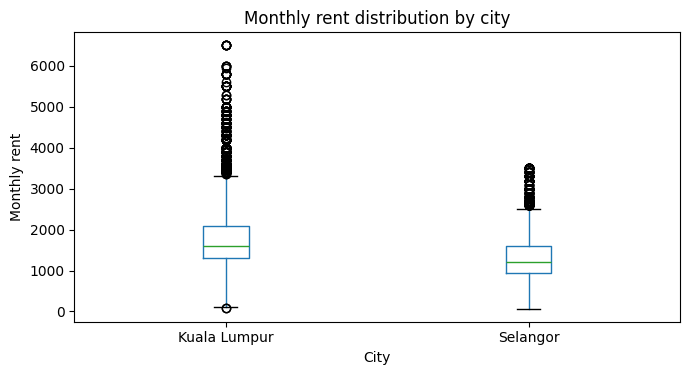

In [6]:
ax = working.boxplot(column="monthly_rent", by="city", grid=False, figsize=(7, 4))
plt.suptitle("")
plt.title("Monthly rent distribution by city")
plt.xlabel("City")
plt.ylabel("Monthly rent")
plt.tight_layout()
plt.show()

The main-market subset shows a clear price difference between the two markets. Kuala Lumpur has both a higher median rent and a wider rent distribution than Selangor. This supports treating city and area as categorical predictors rather than converting area names into an arbitrary numerical rank.

In [7]:
area_summary = (
    working.groupby(["city", "area"])["monthly_rent"]
    .agg(Listings="count", Median_rent="median", Mean_rent="mean")
    .query("Listings >= 50")
    .sort_values("Median_rent", ascending=False)
    .head(10)
)

area_summary

Listings  Median_rent  Mean_rent
city         area                                           
Kuala Lumpur KLCC                236    3,000.000  3,093.305
             Mont Kiara          264    3,000.000  3,138.345
             Bukit Bintang        84    2,400.000  2,776.714
             Titiwangsa           76    2,300.000  2,167.132
             Sri Damansara        69    2,200.000  2,302.855
             Bangsar South       144    2,000.000  2,266.799
             KL City             244    2,000.000  2,239.193
Selangor     Kota Kemuning        62    2,000.000  1,970.145
             Ara Damansara        73    2,000.000  2,070.671
Kuala Lumpur Ampang Hilir         67    2,000.000  2,274.896

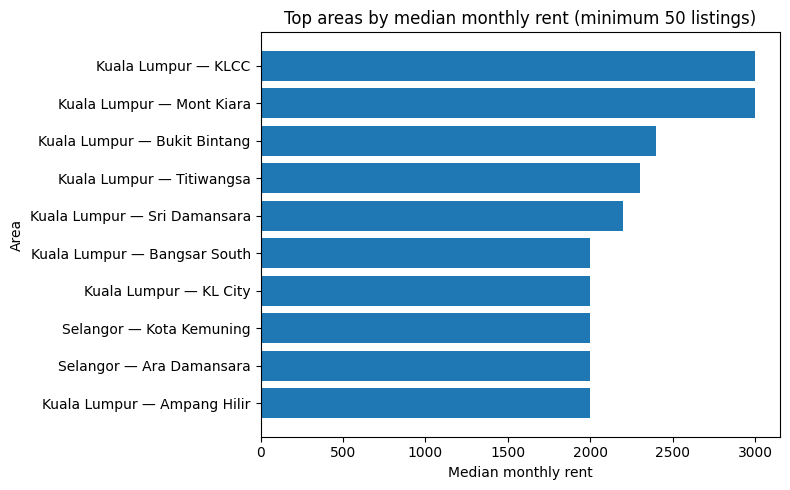

In [8]:
area_plot = area_summary.reset_index()
area_plot["Market"] = area_plot["city"] + " — " + area_plot["area"]

plt.figure(figsize=(8, 5))
plt.barh(area_plot["Market"][::-1], area_plot["Median_rent"][::-1])
plt.title("Top areas by median monthly rent (minimum 50 listings)")
plt.xlabel("Median monthly rent")
plt.ylabel("Area")
plt.tight_layout()
plt.show()

## 4. Modelling Strategy

The original course model converted `area` into an ordered integer based on mean rent and then fitted a one-variable linear regression. That forces an unrealistic assumption that moving from one area code to the next changes rent by a constant amount.

The portfolio revision treats location as a categorical variable through one-hot encoding and evaluates models on a held-out test set.

### Models

1. **Mean baseline** — a reference that always predicts the training-set mean rent.
2. **Area-only Linear Regression** — tests how much `city + area` alone can explain.
3. **Unified Linear Regression** — adds physical and furnishing information.
4. **Ridge Regression** — regularised linear model using the same unified features.
5. **Random Forest** — captures non-linear interactions between property attributes and location.

The data are split 80/20 using a fixed random seed and stratification by city.

In [9]:
target = "monthly_rent"
location_features = ["city", "area"]
numeric_features = ["size", "rooms", "bathroom", "parking"]
categorical_features = ["property_type", "furnished", "city", "area"]
full_features = numeric_features + categorical_features

train_df, test_df = train_test_split(
    working,
    test_size=0.20,
    random_state=42,
    stratify=working["city"],
)

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print("\nTest-set city counts:")
display(test_df["city"].value_counts().to_frame("Rows"))

Training rows: 14411
Test rows: 3603

Test-set city counts:


,Rows
city,
Kuala Lumpur,1809
Selangor,1794


In [10]:
def score_predictions(name, actual, predicted):
    return {
        "Model": name,
        "R2": r2_score(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "MAE": mean_absolute_error(actual, predicted),
    }

results = []
predictions = {}

baseline = DummyRegressor(strategy="mean")
baseline.fit(train_df[full_features], train_df[target])
predictions["Mean Baseline"] = baseline.predict(test_df[full_features])
results.append(score_predictions(
    "Mean Baseline", test_df[target], predictions["Mean Baseline"]
))

location_preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), location_features)
])

location_model = Pipeline([
    ("preprocess", location_preprocessor),
    ("model", LinearRegression()),
])
location_model.fit(train_df[location_features], train_df[target])
predictions["Area-only Linear"] = location_model.predict(test_df[location_features])
results.append(score_predictions(
    "Area-only Linear", test_df[target], predictions["Area-only Linear"]
))

linear_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

linear_model = Pipeline([
    ("preprocess", linear_preprocessor),
    ("model", LinearRegression()),
])
linear_model.fit(train_df[full_features], train_df[target])
predictions["Unified Linear"] = linear_model.predict(test_df[full_features])
results.append(score_predictions(
    "Unified Linear", test_df[target], predictions["Unified Linear"]
))

ridge_model = Pipeline([
    ("preprocess", linear_preprocessor),
    ("model", Ridge(alpha=1.0)),
])
ridge_model.fit(train_df[full_features], train_df[target])
predictions["Ridge"] = ridge_model.predict(test_df[full_features])
results.append(score_predictions(
    "Ridge", test_df[target], predictions["Ridge"]
))

forest_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

forest_model = Pipeline([
    ("preprocess", forest_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=18,
        min_samples_leaf=3,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1,
    )),
])
forest_model.fit(train_df[full_features], train_df[target])
predictions["Random Forest"] = forest_model.predict(test_df[full_features])
results.append(score_predictions(
    "Random Forest", test_df[target], predictions["Random Forest"]
))

results_df = pd.DataFrame(results).set_index("Model").sort_values("R2", ascending=False)
results_df

,R2,RMSE,MAE
Model,,,
Random Forest,0.688,411.504,277.680
Ridge,0.667,424.888,296.423
Unified Linear,0.667,425.102,296.441
Area-only Linear,0.330,602.598,434.931
Mean Baseline,-0.001,736.677,530.889


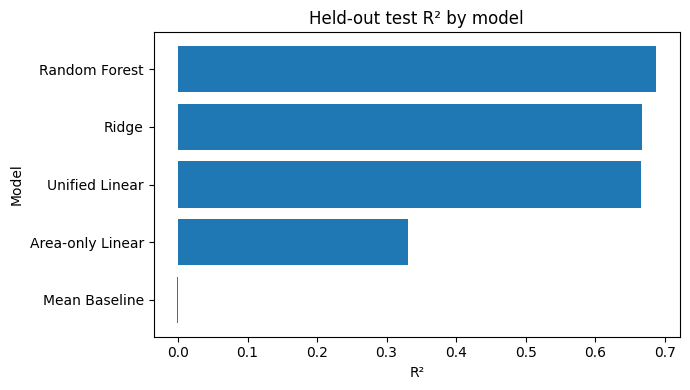

In [11]:
plot_data = results_df.sort_values("R2")

plt.figure(figsize=(7, 4))
plt.barh(plot_data.index, plot_data["R2"])
plt.title("Held-out test R² by model")
plt.xlabel("R²")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

### Model interpretation

The area-only model provides meaningful explanatory power once area is handled as a categorical variable, but the unified models perform substantially better. This indicates that rental price is not explained by location alone; property size, furnishing, property type and other physical attributes add important information.

Random Forest provides the strongest held-out performance among the models tested here. Its feature importances are descriptive model diagnostics, not causal effects.

In [12]:
evaluation = test_df[["city", target]].copy()
evaluation["Random_Forest_Prediction"] = predictions["Random Forest"]

city_model_results = []
for city, group in evaluation.groupby("city"):
    city_model_results.append({
        "City": city,
        "R2": r2_score(group[target], group["Random_Forest_Prediction"]),
        "RMSE": mean_squared_error(
            group[target], group["Random_Forest_Prediction"]
        ) ** 0.5,
        "MAE": mean_absolute_error(
            group[target], group["Random_Forest_Prediction"]
        ),
    })

pd.DataFrame(city_model_results).set_index("City")

,R2,RMSE,MAE
City,,,
Kuala Lumpur,0.650,484.948,326.319
Selangor,0.620,320.851,228.634


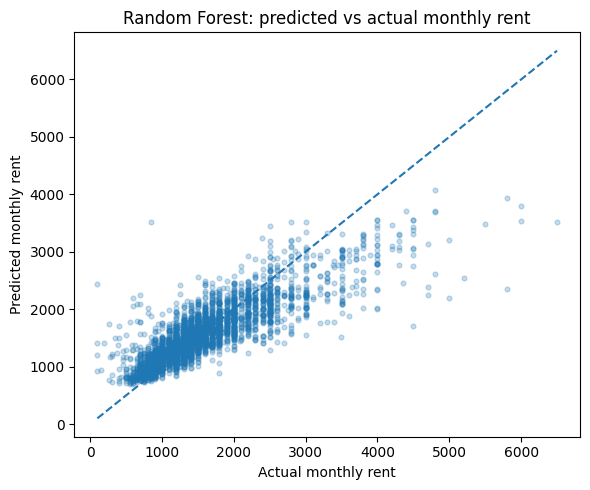

In [13]:
actual = test_df[target].to_numpy()
predicted = predictions["Random Forest"]
low = min(actual.min(), predicted.min())
high = max(actual.max(), predicted.max())

plt.figure(figsize=(6, 5))
plt.scatter(actual, predicted, alpha=0.25, s=12)
plt.plot([low, high], [low, high], linestyle="--")
plt.title("Random Forest: predicted vs actual monthly rent")
plt.xlabel("Actual monthly rent")
plt.ylabel("Predicted monthly rent")
plt.tight_layout()
plt.show()

## 5. Random Forest Feature Importance

In [14]:
feature_names = forest_model.named_steps["preprocess"].get_feature_names_out()
importances = forest_model.named_steps["model"].feature_importances_

importance_table = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances,
}).sort_values("Importance", ascending=False)

group_importance = {}
for feature, importance in zip(feature_names, importances):
    if feature.startswith("numeric__"):
        group = feature.split("__", 1)[1]
    else:
        encoded = feature.split("__", 1)[1]
        group = next(
            (
                column for column in categorical_features
                if encoded.startswith(column + "_")
            ),
            "other",
        )
    group_importance[group] = group_importance.get(group, 0) + importance

group_importance = (
    pd.Series(group_importance, name="Importance")
    .sort_values(ascending=False)
    .to_frame()
)

group_importance

,Importance
furnished,0.249
area,0.194
size,0.166
property_type,0.145
city,0.105
bathroom,0.063
rooms,0.042
parking,0.037


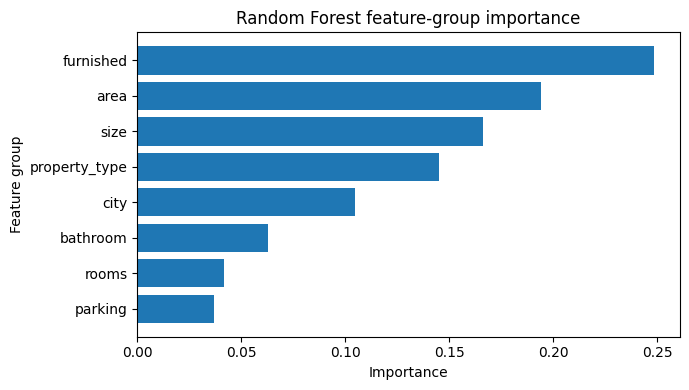

In [15]:
plot_importance = group_importance.sort_values("Importance")

plt.figure(figsize=(7, 4))
plt.barh(plot_importance.index, plot_importance["Importance"])
plt.title("Random Forest feature-group importance")
plt.xlabel("Importance")
plt.ylabel("Feature group")
plt.tight_layout()
plt.show()

## 6. Conclusions

- Kuala Lumpur has a higher and more dispersed rental-price distribution than Selangor in the main-market subset.
- Treating area as a true categorical variable materially improves the location-only model compared with the original ordinal area coding.
- A unified model using physical and categorical property attributes performs much better than location alone.
- Random Forest achieves the best held-out performance among the models compared in this portfolio revision.
- Feature-group importance suggests that furnishing, area, property size, property type and city are all useful predictive inputs, although importance should not be interpreted causally.

## Limitations

- The repository begins from the cleaned dataset exported by the original course project rather than reproducing the raw-data cleaning from the original source file.
- The original notebook did not record a public dataset URL.
- The 99th-percentile modelling filter defines a main-market analysis population and may exclude legitimate luxury listings along with erroneous values.
- The split is random because the dataset has no listing date suitable for chronological validation.
- Random Forest feature importance describes the fitted model, not causal drivers of rent.
- A stronger future version could validate on a separate external dataset or use repeated cross-validation and tuned hyperparameters.